# 02. Оцінка: чи піднімає CNN decode rate

Порівнюємо:
- **raw**: декодер читає кадр як є (baseline);
- **cnn**: кадр спершу проходить через U-Net;
- **raw→cnn**: спершу raw; якщо декодер нічого не прочитав, пробуємо CNN.
  На лінії це дешево: CNN запускається лише для кадрів, які інакше дали б No Read.

Три моделі: **syn** (вчилась на синтетиці), **real** (на train-частині Arte-Lab)
і **mix** (синтетика + реальні фото навпіл).

Метрики: **decode rate** (частка правильно прочитаних), **хибні декоди** (прочитав, але не те),
**мс на кадр** (декодер + CNN, якщо була). Декодери: zxing-cpp (усі формати),
OpenCV (лише EAN-13), WeChat (лише QR).

In [1]:
import sys
from pathlib import Path

# ноутбук лежить у notebooks/, корінь проєкту на рівень вище
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [2]:
import itertools
from tqdm.auto import tqdm

from src.data import generate_synthetic, label_by_consensus, load_artelab, split_by_code
from src.decoders import DECODERS, check, decoders_for
from src.degradations import DEGRADATIONS
from src.model import load_model, restore

models = {
    "syn": load_model(MODELS / "unet_synthetic.pt"),
    "real": load_model(MODELS / "unet_artelab.pt"),
    "mix": load_model(MODELS / "unet_mix.pt"),
}

/Users/andriizemlianyi/venvs/cv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def evaluate(samples, degradations, levels):
    """Таблиця: один рядок = (кадр, декодер, метод) -> outcome, ms."""
    rows = []
    jobs = [(sample, "clean", 0) for sample in samples]
    jobs += list(itertools.product(samples, degradations, levels))
    for sample, name, level in tqdm(jobs):
        if name == "clean":
            image = sample["image"]
        else:
            image = DEGRADATIONS[name](sample["image"], level, seed=level)

        restored, cnn_ms = {}, {}
        for model_name, model in models.items():
            start = time.perf_counter()
            restored[model_name] = restore(model, image)
            cnn_ms[model_name] = (time.perf_counter() - start) * 1000

        for decoder in decoders_for(sample["format"]):
            info = {"sample": sample["id"], "format": sample["format"],
                    "degradation": name, "level": level, "decoder": decoder}

            start = time.perf_counter()
            raw_outcome = check(DECODERS[decoder](image), sample["text"])
            raw_ms = (time.perf_counter() - start) * 1000
            rows.append({**info, "method": "raw", "outcome": raw_outcome, "ms": raw_ms})

            for model_name in models:
                start = time.perf_counter()
                cnn_outcome = check(DECODERS[decoder](restored[model_name]), sample["text"])
                ms = cnn_ms[model_name] + (time.perf_counter() - start) * 1000
                rows.append({**info, "method": "cnn_" + model_name, "outcome": cnn_outcome, "ms": ms})
                # raw->cnn: якщо raw щось прочитав, беремо це (ми не знаємо, чи воно правильне)
                if raw_outcome != "none":
                    rows.append({**info, "method": "raw→cnn_" + model_name,
                                 "outcome": raw_outcome, "ms": raw_ms})
                else:
                    rows.append({**info, "method": "raw→cnn_" + model_name,
                                 "outcome": cnn_outcome, "ms": raw_ms + ms})
    return pd.DataFrame(rows)


def summarize(table, by):
    """decode rate, частка хибних декодів і медіана мс для кожної групи."""
    table = table.assign(correct=table["outcome"] == "correct", wrong=table["outcome"] == "wrong")
    return table.groupby(by).agg(decode_rate=("correct", "mean"), wrong_rate=("wrong", "mean"),
                                 ms=("ms", "median"), frames=("correct", "size")).round(3)


def rate_table(table):
    """decode rate: рядки = пошкодження, колонки = методи, плюс рядок "усі"."""
    rates = summarize(table, ["degradation", "method"])["decode_rate"].unstack()[METHODS]
    rates.loc["усі"] = summarize(table, ["method"])["decode_rate"][METHODS]
    return rates


METHODS = ["raw", "cnn_syn", "raw→cnn_syn", "cnn_real", "raw→cnn_real", "cnn_mix", "raw→cnn_mix"]
CASCADES = ["raw", "raw→cnn_syn", "raw→cnn_real", "raw→cnn_mix"]   # для графіків

## 1. Реальні фото: test-частина Arte-Lab

EAN-13, CC BY 3.0 (Zamberletti, Gallo, Albertini, *Robust Angle Invariant 1D Barcode Detection*, ACPR 2013).
Завантаження: `python scripts/download_artelab.py`.

Вміст кодів у датасеті не вказано, тому правильна відповідь = те, що OpenCV і zxing-cpp
**одностайно** прочитали на оригіналі. Тест = ті товари, яких модель `real` не бачила
(той самий поділ, що в 01). Модель `syn` не бачила жодного реального фото.

In [4]:
artelab = label_by_consensus(load_artelab())
artelab_train, artelab_test = split_by_code(artelab)
print("Test:", len(artelab_test), "фото,", len(set(s["text"] for s in artelab_test)), "кодів")
real = evaluate(artelab_test, list(DEGRADATIONS), [1, 2, 3, 4, 5])
real.to_csv(RESULTS / "artelab.csv", index=False)
summarize(real, ["decoder", "method"])

Test: 87 фото, 19 кодів


  0%|          | 0/3132 [00:00<?, ?it/s]

  0%|          | 1/3132 [00:00<11:10,  4.67it/s]

  0%|          | 2/3132 [00:00<07:43,  6.75it/s]

  0%|          | 4/3132 [00:00<05:56,  8.77it/s]

  0%|          | 5/3132 [00:00<05:58,  8.72it/s]

... (1,568 outputs left out)

100%|█████████▉| 3130/3132 [04:47<00:00, 11.53it/s]

100%|██████████| 3132/3132 [04:48<00:00, 11.52it/s]

100%|██████████| 3132/3132 [04:48<00:00, 10.87it/s]

decode_rate  wrong_rate      ms  frames
decoder method                                               
opencv  cnn_mix             0.676       0.009  22.640    3132
        cnn_real            0.633       0.009  22.643    3132
        cnn_syn             0.580       0.055  23.245    3132
        raw                 0.556       0.004   2.374    3132
        raw→cnn_mix         0.695       0.008   2.751    3132
        raw→cnn_real        0.650       0.008   2.751    3132
        raw→cnn_syn         0.693       0.030   2.751    3132
zxing   cnn_mix             0.653       0.007  24.683    3132
        cnn_real            0.641       0.003  24.623    3132
        cnn_syn             0.603       0.004  25.852    3132
        raw                 0.452       0.011   3.801    3132
        raw→cnn_mix         0.682       0.015  25.501    3132
        raw→cnn_real        0.655       0.012  25.410    3132
        raw→cnn_syn         0.692       0.012  27.238    3132

### Decode rate за типом пошкодження (zxing-cpp)

In [5]:
real_zxing = real[real["decoder"] == "zxing"]
rate_table(real_zxing)

method,raw,cnn_syn,raw→cnn_syn,cnn_real,raw→cnn_real,cnn_mix,raw→cnn_mix
degradation,,,,,,,
clean,1.000,0.862,1.000,0.977,1.000,0.931,1.000
dark,0.437,0.802,0.855,0.694,0.694,0.731,0.754
defocus,0.216,0.202,0.329,0.244,0.269,0.331,0.352
glare,0.439,0.644,0.687,0.572,0.598,0.653,0.680
jpeg,0.745,0.791,0.920,0.922,0.945,0.887,0.924
motion_blur,0.193,0.120,0.216,0.223,0.234,0.225,0.244
noise,0.398,0.784,0.837,0.885,0.892,0.874,0.887
uneven,0.628,0.828,0.940,0.878,0.885,0.814,0.871
усі,0.452,0.603,0.692,0.641,0.655,0.653,0.682


## 2. Синтетика: незнайомі коди (test, seed 2)

30 кодів кожного формату × (чистий + 7 пошкоджень × 5 рівнів).

In [6]:
synthetic_test = generate_synthetic(n_per_format=30, seed=2)
synthetic = evaluate(synthetic_test, list(DEGRADATIONS), [1, 2, 3, 4, 5])
synthetic.to_csv(RESULTS / "synthetic.csv", index=False)
summarize(synthetic, ["decoder", "method"])

  0%|          | 0/3240 [00:00<?, ?it/s]

  0%|          | 2/3240 [00:00<03:16, 16.45it/s]

  0%|          | 5/3240 [00:00<02:24, 22.45it/s]

  0%|          | 9/3240 [00:00<02:18, 23.28it/s]

  0%|          | 13/3240 [00:00<01:54, 28.08it/s]

  0%|          | 16/3240 [00:00<01:56, 27.69it/s]

... (774 outputs left out)

100%|█████████▉| 3231/3240 [01:46<00:00, 28.50it/s]

100%|█████████▉| 3235/3240 [01:46<00:00, 26.30it/s]

100%|██████████| 3240/3240 [01:46<00:00, 30.48it/s]

decode_rate  wrong_rate     ms  frames
decoder method                                              
opencv  cnn_mix             0.726       0.006  8.890    1080
        cnn_real            0.712       0.012  9.182    1080
        cnn_syn             0.707       0.005  9.303    1080
        raw                 0.575       0.008  1.294    1080
        raw→cnn_mix         0.771       0.015  1.621    1080
        raw→cnn_real        0.721       0.017  1.621    1080
        raw→cnn_syn         0.802       0.012  1.621    1080
wechat  cnn_mix             0.601       0.000  5.621    1080
        cnn_real            0.640       0.000  6.499    1080
        cnn_syn             0.689       0.000  6.226    1080
        raw                 0.708       0.000  2.222    1080
        raw→cnn_mix         0.723       0.000  2.222    1080
        raw→cnn_real        0.720       0.000  2.222    1080
        raw→cnn_syn         0.740       0.000  2.222    1080
zxing   cnn_mix             0.722       0.001  5.847    3240
        cnn_real            0.648       0.000  5.911    3240
        cnn_syn             0.771       0.001  6.341    3240
        raw                 0.558       0.001  0.804    3240
        raw→cnn_mix         0.738       0.001  2.264    3240
        raw→cnn_real        0.682       0.001  2.264    3240
        raw→cnn_syn         0.784       0.002  2.264    3240

In [7]:
synthetic_zxing = synthetic[synthetic["decoder"] == "zxing"]
rate_table(synthetic_zxing)

method,raw,cnn_syn,raw→cnn_syn,cnn_real,raw→cnn_real,cnn_mix,raw→cnn_mix
degradation,,,,,,,
clean,0.978,0.911,0.978,0.911,0.978,0.911,0.978
dark,0.613,0.882,0.907,0.831,0.856,0.804,0.833
defocus,0.271,0.620,0.618,0.273,0.316,0.451,0.449
glare,0.711,0.778,0.784,0.764,0.811,0.769,0.773
jpeg,0.887,0.911,0.911,0.849,0.904,0.887,0.904
motion_blur,0.200,0.356,0.356,0.218,0.233,0.284,0.284
noise,0.660,0.911,0.911,0.911,0.911,0.911,0.911
uneven,0.478,0.911,0.960,0.638,0.687,0.911,0.960
усі,0.558,0.771,0.784,0.648,0.682,0.722,0.738


### За форматом коду (zxing-cpp)

In [8]:
summarize(synthetic_zxing, ["format", "method"])["decode_rate"].unstack()[METHODS]

method,raw,cnn_syn,raw→cnn_syn,cnn_real,raw→cnn_real,cnn_mix,raw→cnn_mix
format,,,,,,,
CODE128,0.579,0.864,0.864,0.694,0.724,0.802,0.808
EAN13,0.555,0.872,0.875,0.724,0.740,0.805,0.807
QR,0.540,0.577,0.612,0.527,0.583,0.560,0.597


## 3. Графіки

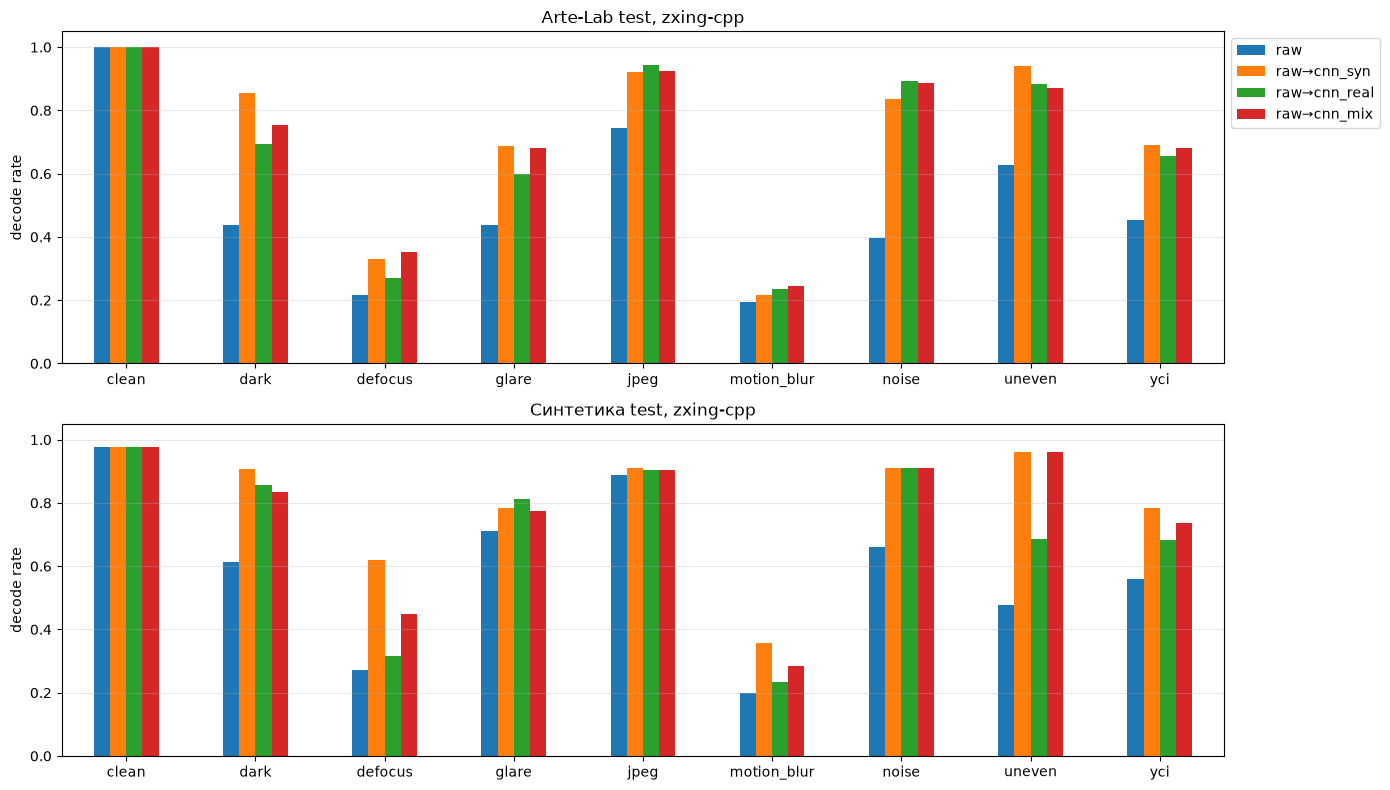

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharey=True)
for ax, (title, part) in zip(axes, [("Arte-Lab test", real_zxing), ("Синтетика test", synthetic_zxing)]):
    rate_table(part)[CASCADES].plot.bar(ax=ax, rot=0, legend=False)
    ax.set_title(title + ", zxing-cpp")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("")
    ax.set_ylabel("decode rate")
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig(RESULTS / "fig_overall.png", dpi=100)
plt.show()

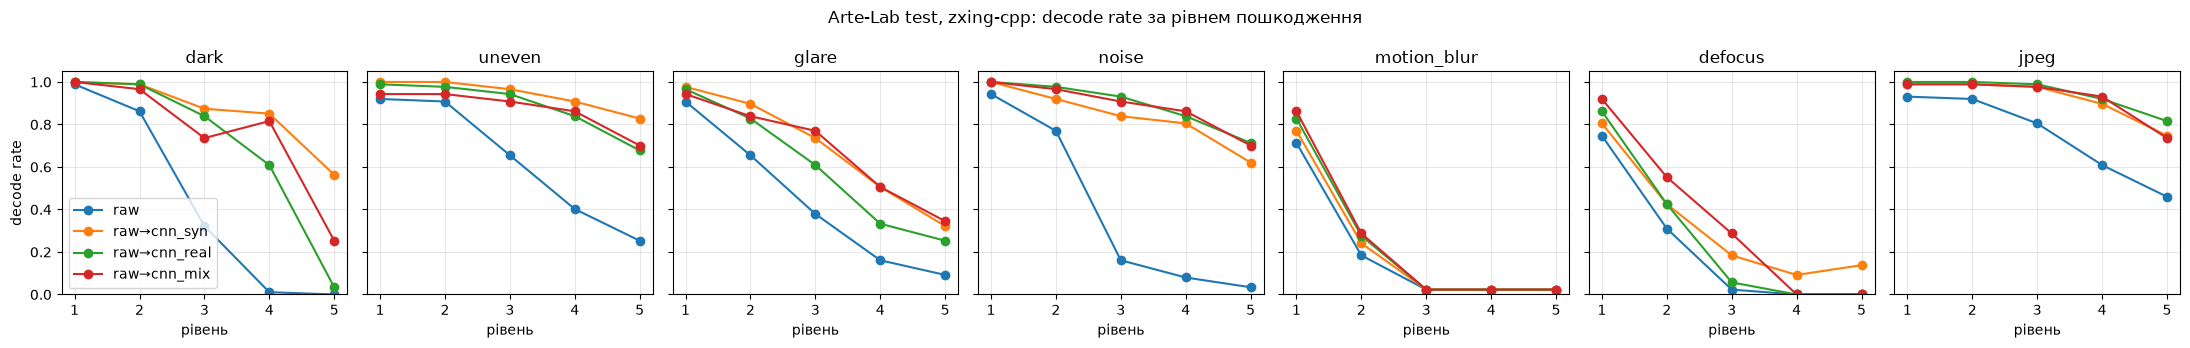

In [10]:
names = list(DEGRADATIONS)
fig, axes = plt.subplots(1, len(names), figsize=(22, 3.5), sharey=True)
for ax, name in zip(axes, names):
    part = summarize(real_zxing[real_zxing["degradation"] == name], ["level", "method"])["decode_rate"].unstack()
    for method in CASCADES:
        ax.plot(part.index, part[method], marker="o", label=method)
    ax.set_title(name)
    ax.set_xlabel("рівень")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("decode rate")
axes[0].legend()
plt.suptitle("Arte-Lab test, zxing-cpp: decode rate за рівнем пошкодження")
plt.tight_layout()
plt.savefig(RESULTS / "fig_levels.png", dpi=100)
plt.show()

### Приклади на test-фото: вхід і три моделі

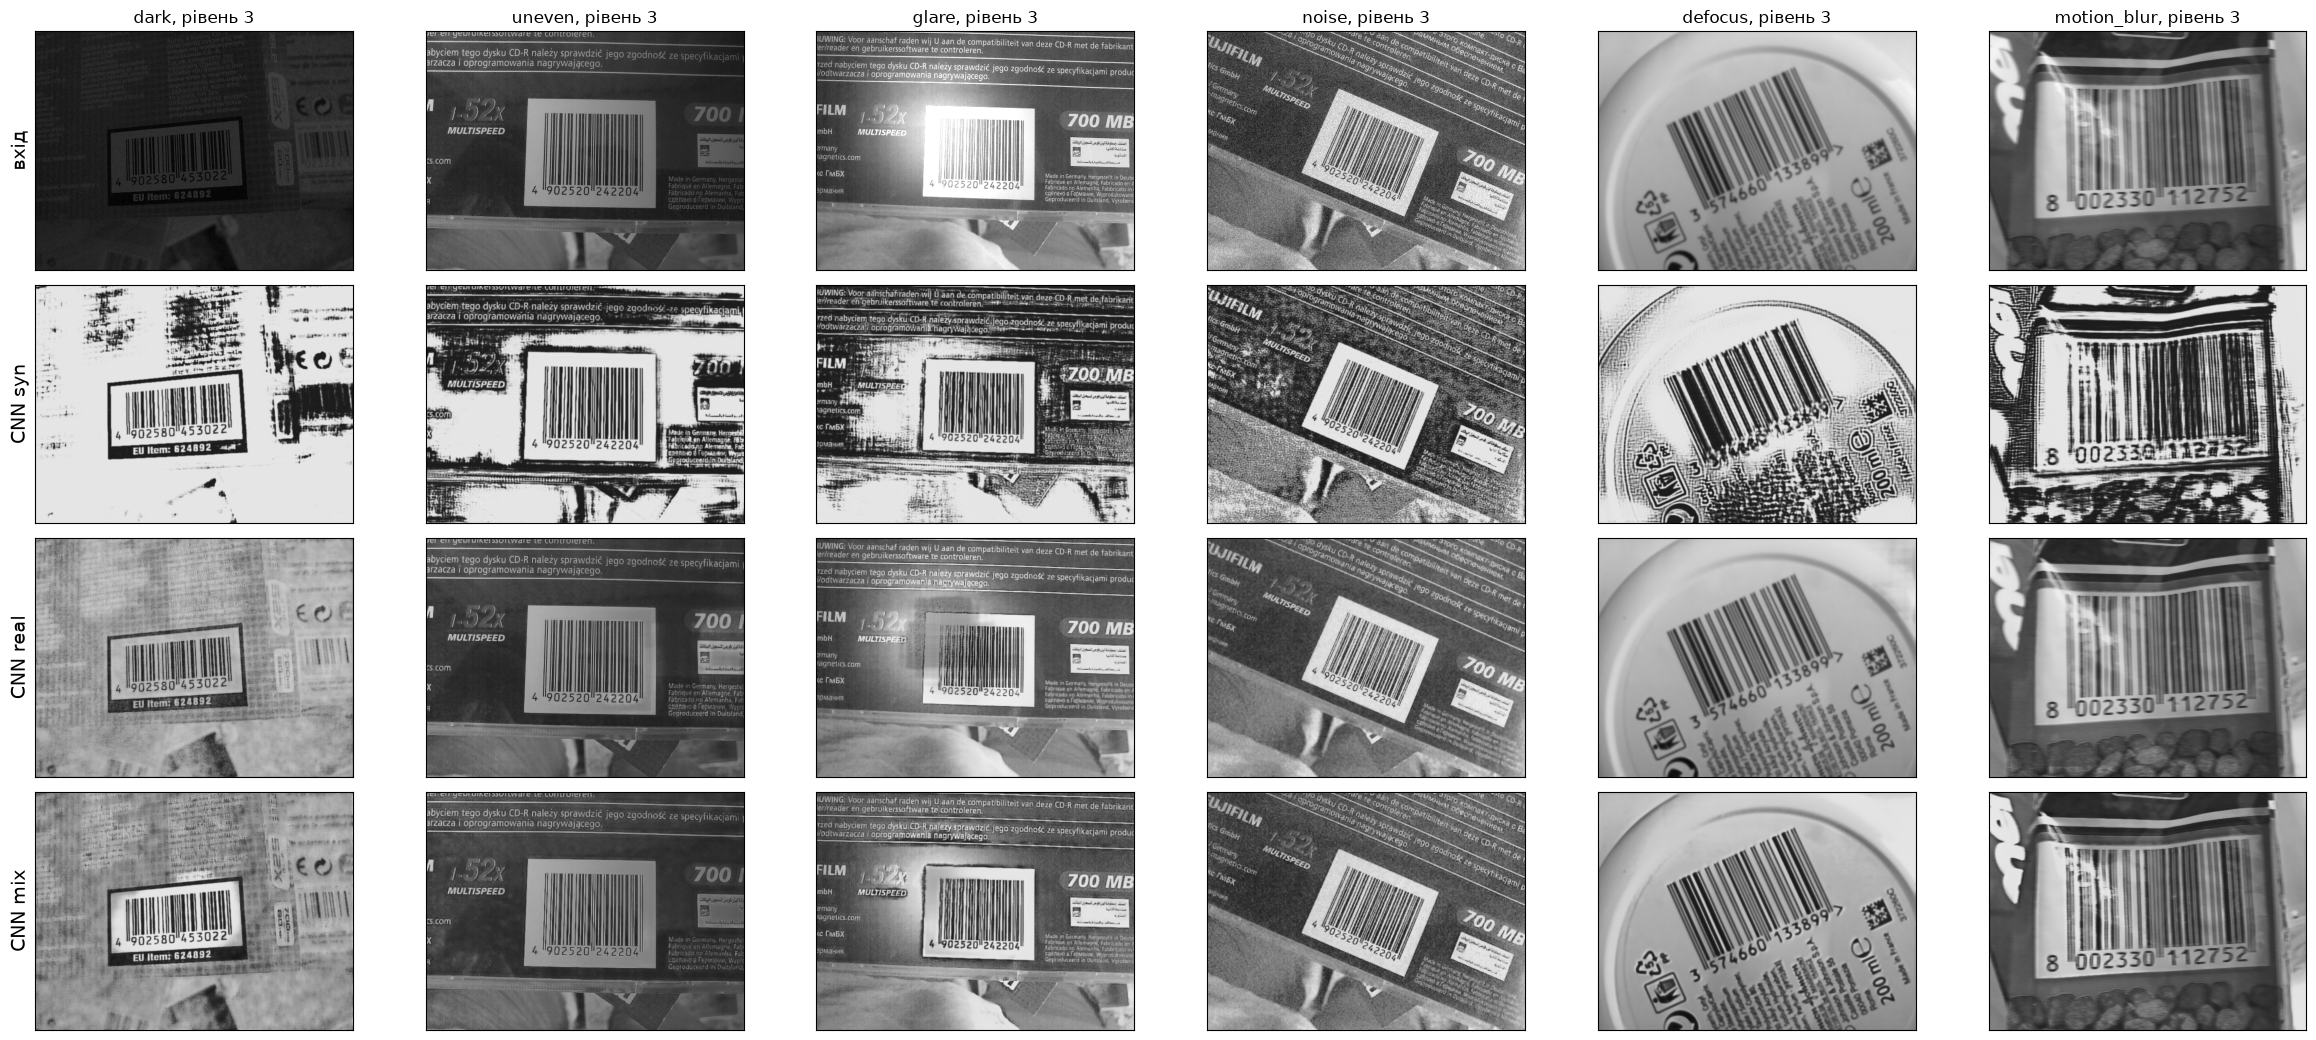

In [11]:
examples = ["dark", "uneven", "glare", "noise", "defocus", "motion_blur"]
fig, axes = plt.subplots(4, len(examples), figsize=(24, 10.5))
for i, name in enumerate(examples):
    damaged = DEGRADATIONS[name](artelab_test[i * 3]["image"], 3, seed=3)
    images = [damaged] + [restore(models[name], damaged) for name in models]
    for row, image in enumerate(images):
        axes[row, i].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[0, i].set_title(name + ", рівень 3")
for row, label in enumerate(["вхід", "CNN syn", "CNN real", "CNN mix"]):
    axes[row, 0].set_ylabel(label, fontsize=14)
plt.tight_layout()
plt.savefig(RESULTS / "examples.png", dpi=80)
plt.show()

## Висновки

Arte-Lab test (87 фото, 19 товарів, яких моделі real і mix не бачили):

| | raw | raw→cnn_syn | raw→cnn_real | raw→cnn_mix |
|---|---|---|---|---|
| zxing-cpp, decode rate | 45% | 69% | 66% | 68% |
| OpenCV, decode rate | 56% | 69% | 65% | **70%** |
| OpenCV, хибні декоди | 0.4% | 3.0% | 0.8% | **0.8%** |
| CNN без raw, чисті кадри (zxing) | 100% | 86% | 98% | 93% |

- **CNN піднімає decode rate з усіма моделями:** +20-25 п.п. на реальних фото,
  найбільше на темряві, нерівному світлі, шумі й JPEG.
- **mix поєднує сильні сторони:** decode rate на рівні syn, а хибних декодів так само мало,
  як у real. Сама по собі (без raw) mix найкраща: zxing 65%, OpenCV 68%.
- **syn "домальовує" текстури** на фоні реальних фото, звідси 3-5% хибних декодів з OpenCV.
- **Розмиття на реальних фото не виправляє жодна модель** (defocus, motion_blur ≈ raw + 5-10 п.п.).
  Ціль real/mix = оригінальне фото, яке саме не ідеально різке; syn вміє лише на синтетиці.
- **Без overfitting:** test loss не росте (fig_training.png).
- **Різниця 1-3 п.п. між моделями ненадійна** (87 фото), різниця з raw (+20 п.п.) надійна.
- **Вибір для лінії: raw→cnn_mix.** Хибне читання гірше за No Read, а mix дає найменше хибних
  при найвищому decode rate.
- **Час:** CNN ~25 мс на фото 640×480 (Mac Mini M4, MPS), у raw→cnn лише для кадрів з No Read.
